In [ ]:
import pandas as pd
from pandas import DataFrame
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import matplotlib.pyplot as plt 
import pandas as pd
from kmodes.kprototypes import KPrototypes, kmodes
import seaborn as snb
from sklearn.metrics import silhouette_score

In [151]:
# %pip install kmodes

In [2]:
df = pd.read_csv(r'C:\Users\marco\OneDrive\Documents\CS\Intern\Bootcamp TCS\bootcampia\base_dados\pesquisa_ti\dados.csv')

In [153]:
# scal_altura = MinMaxScaler()
# df['altura'] = scal_altura.fit_transform(df[['altura']])

# scal_idade = MinMaxScaler()
# df['idade'] = scal_altura.fit_transform(df[['idade']])

In [7]:
df.dtypes

Carimbo de data/hora                                             object
Região onde mora:                                                object
Gênero:                                                          object
Escolaridade:                                                    object
A formação é na área de tecnologia?                              object
Tempo de atuação na área de tecnologia:                          object
Área de atuação que mais se adequa para sua realidade:           object
Cargo que mais se adequa para a sua realidade:                   object
Senioridade que se aplica para a sua realidade:                  object
Faixa salarial mensal:                                           object
Modalidade de trabalho que se aplica para a sua realidade:       object
Modalidade de atuação que se aplica para sua realidade:          object
Segmento do local onde trabalha que mais se adequa as opções:    object
Perfil da empresa onde trabalha e tipo de alocação:             

In [13]:
df.head(5)

,Carimbo de data/hora,Região onde mora:,Gênero:,Escolaridade:,A formação é na área de tecnologia?,Tempo de atuação na área de tecnologia:,Área de atuação que mais se adequa para sua realidade:,Cargo que mais se adequa para a sua realidade:,Senioridade que se aplica para a sua realidade:,Faixa salarial mensal:,Modalidade de trabalho que se aplica para a sua realidade:,Modalidade de atuação que se aplica para sua realidade:,Segmento do local onde trabalha que mais se adequa as opções:,Perfil da empresa onde trabalha e tipo de alocação:,Nível de satisfação com o mercado de trabalho:
0,2026/09/22 2:15:12 PM GMT-3,Sul,Masculino cis,Superior completo,Sim,6 a 10 anos,Desenvolvimento de Software,Liderança Técnica/Gestão,Sênior,mais que 15 mil reais,Autônomo/Horista/Prestador de serviço,Remoto,Empresa de tecnologia que oferta produtos (Ex:...,Não se aplica,5
1,2026/09/22 2:20:52 PM GMT-3,Centro-Oeste,Masculino cis,Pós-graduado,Sim,mais que 10 anos,Desenvolvimento de Software,Desenvolvedor/Analista/Operacional,Sênior,mais que 15 mil reais,PJ,Remoto,Empresa de tecnologia que oferta produtos (Ex:...,Multinacional Brasileira - Alocado em time nac...,4
2,2026/09/22 2:21:09 PM GMT-3,Sul,Masculino cis,Pós-graduado,Sim,mais que 10 anos,Infraestrutura,Desenvolvedor/Analista/Operacional,Sênior,entre 8 mil a 15 mil reais,CLT,Presencial,Empresa que não é do ramo mas tem setor de tec...,Nacional,3
3,2026/09/22 2:22:46 PM GMT-3,Sul,Masculino cis,Mestre,Sim,mais que 10 anos,Ciência de Dados/BI/IA,C-level/Diretor,Sênior,entre 8 mil a 15 mil reais,CLT,Presencial,Empresa de tecnologia que oferta produtos (Ex:...,Nacional,5
4,2026/09/22 2:23:26 PM GMT-3,Sudeste,Masculino cis,Pós-graduado,Sim,mais que 10 anos,Desenvolvimento de Software,Desenvolvedor/Analista/Operacional,Sênior,mais que 15 mil reais,CLT,Remoto,Empresa de tecnologia que oferta produtos (Ex:...,Multinacional Estrangeira - Alocado em time co...,4


In [ ]:
df.drop(columns='Carimbo de data/hora')

In [ ]:
model = KPrototypes(
    n_clusters=4,
    random_state=42
)

# check how to treat the data that's categorical, but hierarquical

cat_cols = ['Carimbo de data/hora', 'Região onde mora:', 'Gênero:', 'Escolaridade:', 'A formação é na área de tecnologia?', 
            'Tempo de atuação na área de tecnologia:', 'Área de atuação que mais se adequa para sua realidade:',
            'Cargo que mais se adequa para a sua realidade:', 'Senioridade que se aplica para a sua realidade:',
            'Faixa salarial mensal:', 'Modalidade de trabalho que se aplica para a sua realidade:', 'Modalidade de atuação que se aplica para sua realidade:',
            'Segmento do local onde trabalha que mais se adequa as opções:', 'Perfil da empresa onde trabalha e tipo de alocação:']

categorical_indices = [
    df.columns.get_loc(column)
    for column in cat_cols
]


clusters = model.fit_predict(
    df,
    categorical=categorical_indices
)

In [165]:
print(clusters)

[0 1 1 0 0 0 0 0 0 0 0 0 0 1 1 1 1 0 0 0 0 0 0 0 0 0 1 0 0 1 0 1 1 0 1 1 0
 1 0 0]


In [167]:
df["cluster"] = clusters

In [158]:
df.to_csv("dados_clusterizados.csv", index=False)

In [159]:
def plot_histograma(df: DataFrame , col: str):
    graphs = snb.displot(data=df, x=col, hue='cluster', col='cluster', aspect=0.6)

    for ax in graphs.axes.flat:
        ax.tick_params(axis='x', labelrotation=90)
    


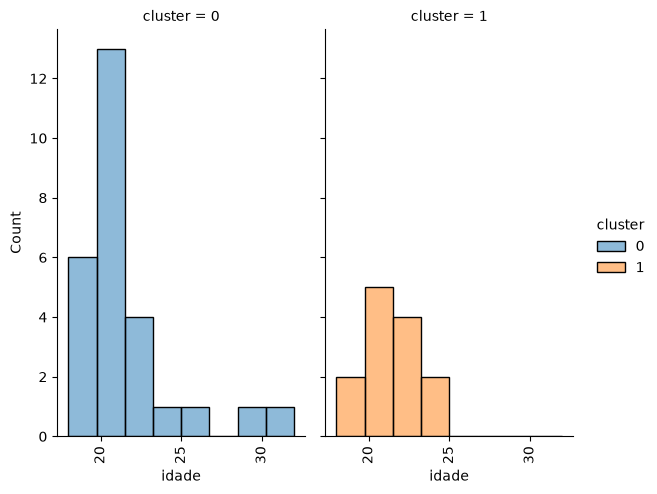

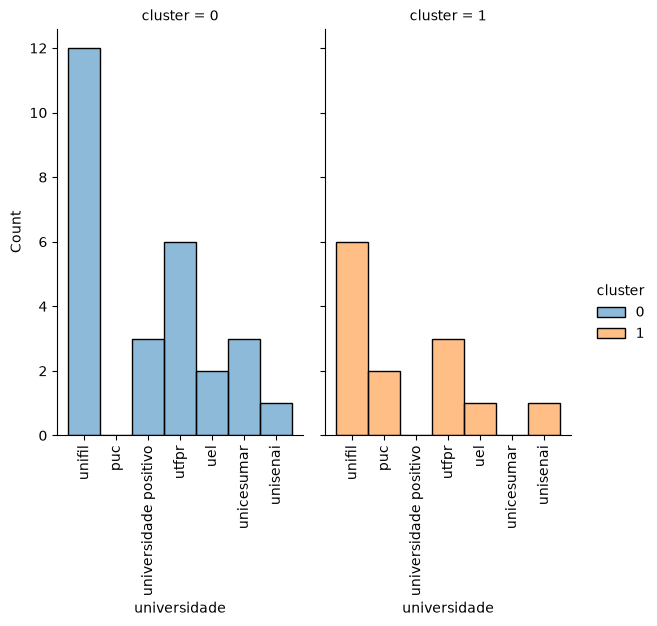

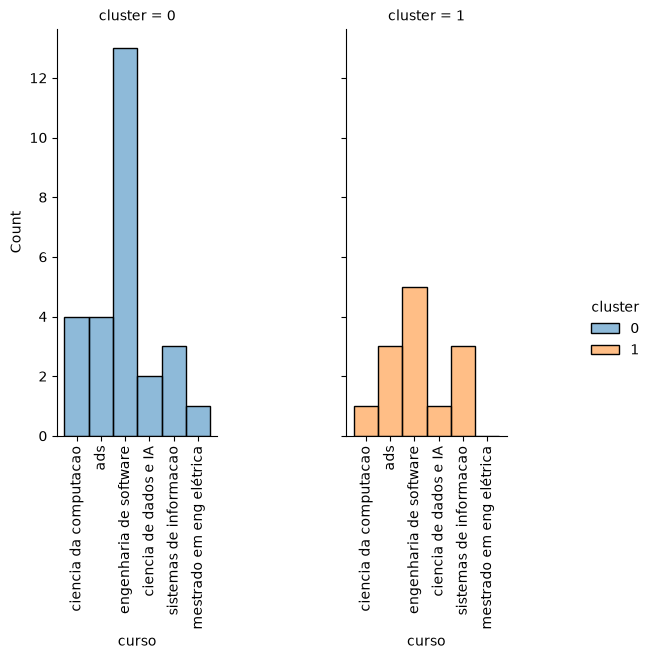

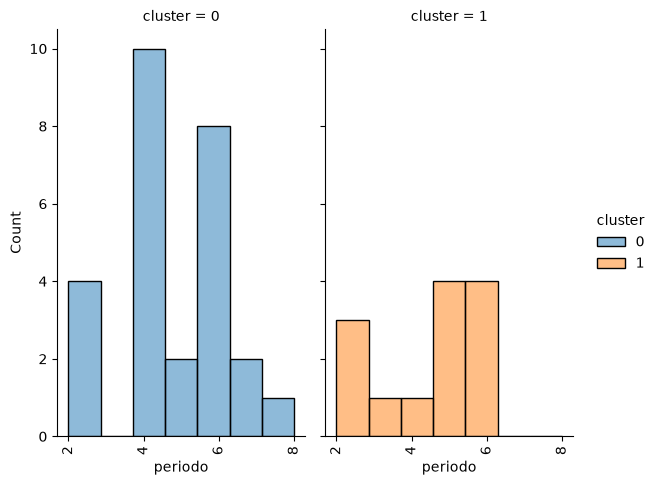

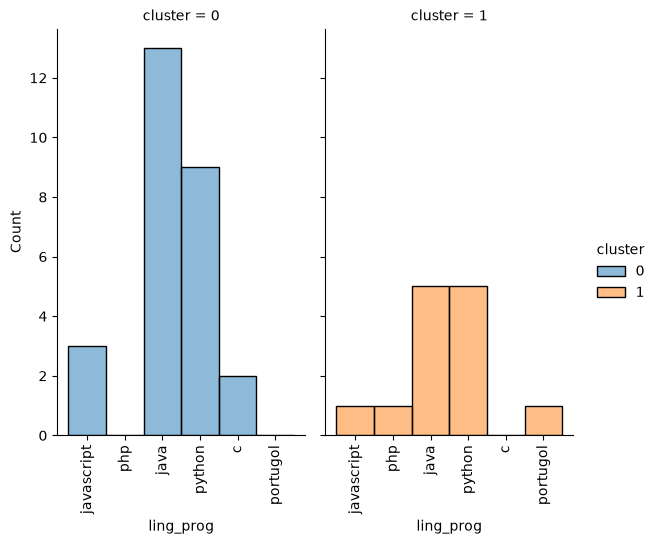

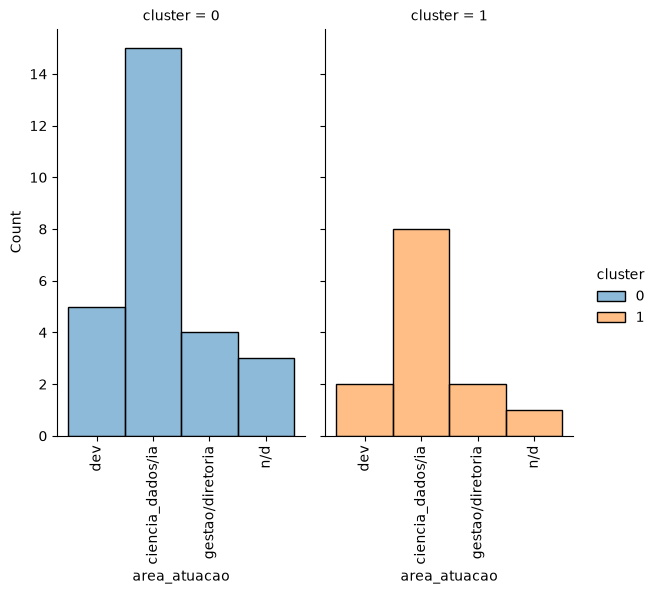

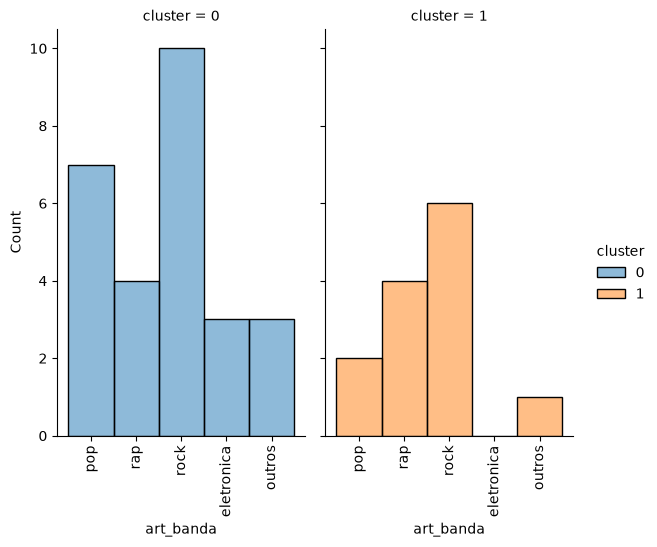

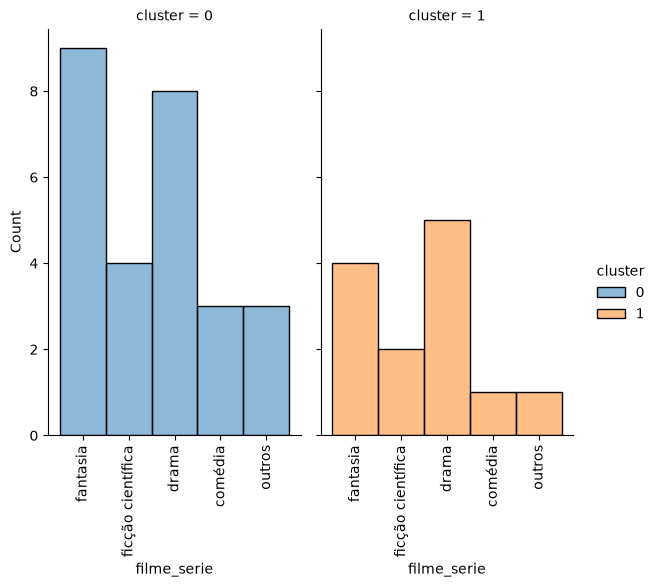

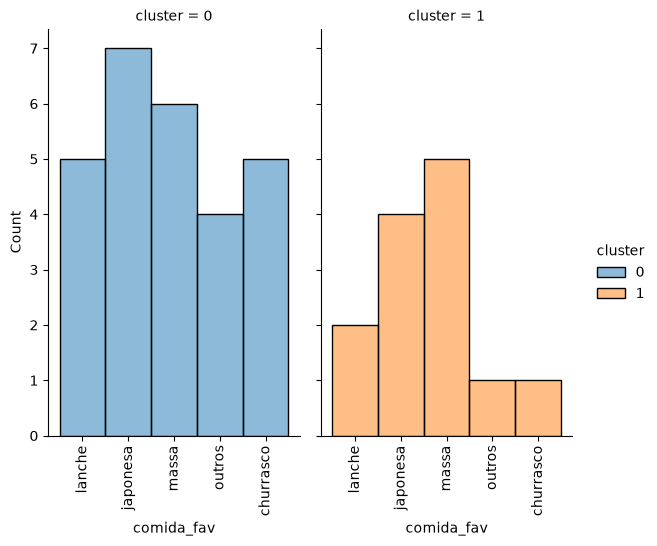

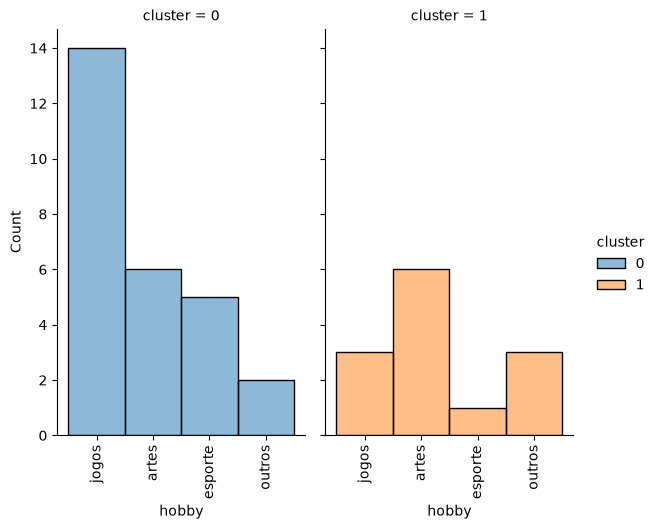

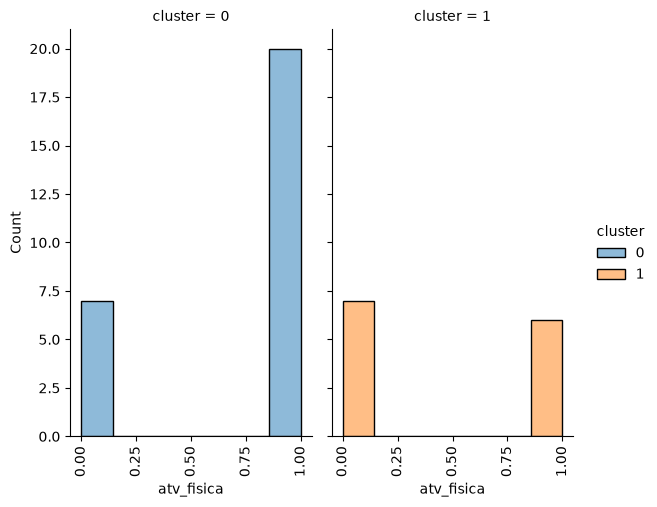

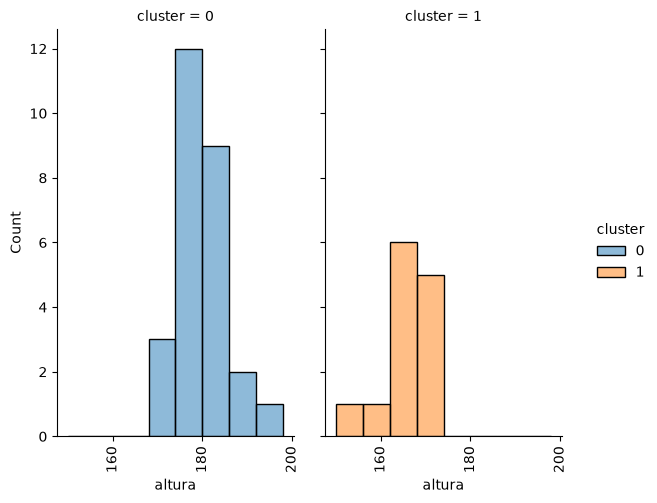

In [168]:
for col in df.columns:
    if col != 'cluster': 
        plot_histograma(df, col)

In [169]:
silhouette_score(pd.get_dummies(df.drop(columns="cluster")).astype(float), clusters)

0.4373676014589356